# Project 1 — Global education systems
## Session 4: link the dataframes and choose the indicators

**AI Clinic · PGE1**

### Context
EducationTech wants to expand internationally and asks whether the World Bank's EdStats data can help choose countries or regions.
Session 2 loaded the five files and mapped how they are linked; session 3 built a clean, linked table.
This session goes one step further: **choose the indicators, build one row per country and rank the countries.**

### Objectives of the session
1. Check that the **indicator codes** match between `series` and `data` (section 1).
2. Keep **only the countries** in `data`, and **remove the projections** (PRJ) (section 2).
3. Find the **best-filled recent year(s)**, to know which period to work on (section 3).
4. **Choose a few indicators** to answer the company's question (where to expand?), justify the choice and check their coverage (section 5).
5. Build a **table with one row per country and one column per indicator**, over a reference period (section 6).
6. **Rank the countries** according to the chosen indicators (section 7).
7. Propose and plot **relevant charts** (sections 4 and 8).

Two decisions taken with the teacher and the group frame this notebook:
* **Period:** the teacher asked for three years; we work on **2012–2014** (section 3 checks that this is the right choice).
* **Business hypothesis:** the brief does not say what EducationTech sells. We assume **a paid online learning platform for
  upper-secondary and university students**. This hypothesis drives the choice of indicators (section 5).

Only `data`, `country` and `series` are needed here. The two note files (`country_series`, `footnote`) are not used in this session.

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY, ORANGE = "#3b6ea5", "#b0b7c3", "#c8753a"

DATA_DIR = Path(os.environ.get("EDSTATS_DIR", "."))
OUT_DIR = Path(os.environ.get("EDSTATS_OUT", "output")); OUT_DIR.mkdir(exist_ok=True)

data = pd.read_csv(DATA_DIR / "EdStatsData.csv")
country = pd.read_csv(DATA_DIR / "EdStatsCountry.csv")
series = pd.read_csv(DATA_DIR / "EdStatsSeries.csv")

# Empty columns created by a trailing comma at the end of each CSV line (seen in session 2)
data = data.drop(columns="Unnamed: 69")
country = country.drop(columns="Unnamed: 31")
series = series.drop(columns="Unnamed: 20")

year_cols = [c for c in data.columns if c.isdigit()]
print("data:", data.shape, "| country:", country.shape, "| series:", series.shape)

data: (886930, 69) | country: (241, 31) | series: (3665, 20)


## 1. Do the indicator codes match between `series` and `data`?

In [2]:
codes_data = set(data["Indicator Code"])
codes_series = set(series["Series Code"])
print("codes in data            :", len(codes_data))
print("codes in series          :", len(codes_series))
print("found in both, as written:", len(codes_data & codes_series))
print("in data only             :", len(codes_data - codes_series))
print("in series only           :", len(codes_series - codes_data))

codes in data            : 3665
codes in series          : 3665
found in both, as written: 3612
in data only             : 53
in series only           : 53


In [3]:
# The unmatched codes, side by side (repr() makes spaces visible)
only_data = sorted(codes_data - codes_series)
lookup = {s.strip().upper(): s for s in codes_series}
pairs = pd.DataFrame({"in data": only_data, "in series": [repr(lookup.get(c.strip().upper())) for c in only_data]})
pairs["difference"] = np.where(pairs["in series"].str.endswith(" '"), "trailing space", "letter case")
print(pairs["difference"].value_counts().to_string())
pairs.head(6)

difference
letter case       50
trailing space     3


,in data,in series,difference
0,SE.SEC.DURS.LO,'SE.SEC.DURS.LO ',trailing space
1,SE.SEC.ENRR.UP.FE,'SE.SEC.ENRR.UP.FE ',trailing space
2,UIS.AIR.1.GLAST.GPI,'UIS.AIR.1.Glast.GPI',letter case
3,UIS.CEAGE.1,'UIS.CEAge.1',letter case
4,UIS.E.0.PU.F,'UIS.E.0.Pu.F',letter case
5,UIS.E.1.GUK,'UIS.E.1.Guk',letter case


Every unmatched code has a twin on the other side: the difference is only a **trailing space** or the **letter case**.
We normalise both columns the same way — remove spaces, write in upper case — and test again.

In [4]:
def norm_code(s):
    """Normalise an indicator code: no surrounding spaces, upper case."""
    return s.str.strip().str.upper()

data["Indicator Code"] = norm_code(data["Indicator Code"])
series["Series Code"] = norm_code(series["Series Code"])

codes_data, codes_series = set(data["Indicator Code"]), set(series["Series Code"])
print("after normalisation -> in both:", len(codes_data & codes_series),
      "| data only:", len(codes_data - codes_series), "| series only:", len(codes_series - codes_data))
print("codes still unique in series:", series["Series Code"].is_unique)
print("still one row per (country, indicator) in data:", not data.duplicated(["Country Code", "Indicator Code"]).any())

after normalisation -> in both: 3665 | data only: 0 | series only: 0
codes still unique in series: True
still one row per (country, indicator) in data: True


In [5]:
# Same code, same name?
names = data[["Indicator Code", "Indicator Name"]].drop_duplicates().merge(
    series[["Series Code", "Indicator Name"]], left_on="Indicator Code", right_on="Series Code", suffixes=(" (data)", " (series)"))
diff = names[names["Indicator Name (data)"] != names["Indicator Name (series)"]]
print(f"indicators whose name differs between the two files: {len(diff)} of {len(names)}")
diff[["Indicator Code", "Indicator Name (data)", "Indicator Name (series)"]].head(5)

indicators whose name differs between the two files: 462 of 3665


,Indicator Code,Indicator Name (data),Indicator Name (series)
1242,NY.GDP.MKTP.KD,GDP at market prices (constant 2005 US$),GDP (constant 2010 US$)
1243,NY.GDP.MKTP.CD,GDP at market prices (current US$),GDP (current US$)
1244,NY.GDP.PCAP.KD,GDP per capita (constant 2005 US$),GDP per capita (constant 2010 US$)
1376,SL.TLF.ADVN.ZS,Labor force with advanced education (% of total),Labor force with advanced education (% of total working-age population with ...
1377,SL.TLF.ADVN.FE.ZS,"Labor force with advanced education, female (% of female labor force)","Labor force with advanced education, female (% of female working-age populat..."


**Result.** After normalisation, the 3,665 codes match one to one. The link `data` ↔ `series` is now reliable.

One reservation: **462 indicators have a different name** in the two files. Some differences are only wording, but some change the meaning
(GDP in *constant 2005 US$* in `data`, *constant 2010 US$* in `series`). We keep the name from `data`, which goes with the values,
and we will check the definition in `series` for every indicator we finally select.

## 2. Keep only the countries

### 2.1 Why it matters

In [6]:
pop = data.loc[data["Indicator Code"] == "SP.POP.TOTL"].set_index("Country Code")["2015"]
print(f"World population in 2015 (row 'World')       : {pop['WLD'] / 1e9:5.2f} billion")
print(f"Sum of the column over all 242 rows of data  : {pop.sum() / 1e9:5.2f} billion")

World population in 2015 (row 'World')       :  7.36 billion
Sum of the column over all 242 rows of data  : 47.53 billion


Adding up every row gives **more than six times the world population**: each inhabitant is counted in their country, in their region,
in their income group, in "World"… Any total or average computed on all rows is wrong.

### 2.2 Which rows are aggregates?
`country` should help: aggregates have no `Region`. Let us check that rule rather than trust it.

In [7]:
no_region = country.loc[country["Region"].isna(), ["Country Code", "Short Name", "Income Group"]]
print(f"rows of country without a Region: {len(no_region)}")
display(no_region)

missing_from_country = sorted(set(data["Country Code"]) - set(country["Country Code"]))
print("codes in data that are absent from country:",
      data.loc[data["Country Code"].isin(missing_from_country), ["Country Code", "Country Name"]].drop_duplicates().values.tolist())

rows of country without a Region: 27


,Country Code,Short Name,Income Group
5,ARB,Arab World,NaN
57,EAP,East Asia & Pacific (developing only),NaN
58,EAS,East Asia & Pacific (all income levels),NaN
59,ECA,Europe & Central Asia (developing only),NaN
60,ECS,Europe & Central Asia (all income levels),NaN
63,EMU,Euro area,NaN
68,EUU,European Union,NaN
78,GIB,Gibraltar,NaN
89,HIC,High income,NaN
92,HPC,Heavily indebted poor countries (HIPC),NaN


codes in data that are absent from country: [['VGB', 'British Virgin Islands']]


The rule *"no Region = aggregate"* is **almost** right, with three exceptions:

* **Gibraltar (`GIB`)** and **Nauru (`NRU`)** have no region, yet they are real territories;
* **British Virgin Islands (`VGB`)** is in `data` but has no row in `country` at all.

So the aggregates are *the rows without a region, except Gibraltar and Nauru*.
The three territories are given their World Bank region by hand, so that every country has one.

In [8]:
REAL_WITHOUT_REGION = {"GIB", "NRU"}
aggregates = set(country.loc[country["Region"].isna(), "Country Code"]) - REAL_WITHOUT_REGION
print("aggregates:", len(aggregates))

# Country reference table: one row per real country, with region and income group
countries = (data[["Country Code", "Country Name"]].drop_duplicates()
             .query("`Country Code` not in @aggregates")
             .merge(country[["Country Code", "Region", "Income Group"]], on="Country Code", how="left", validate="one_to_one"))

# World Bank classification of the three territories without a region
manual_region = {"GIB": "Europe & Central Asia", "NRU": "East Asia & Pacific", "VGB": "Latin America & Caribbean"}
countries["Region"] = countries["Region"].fillna(countries["Country Code"].map(manual_region))
print("countries:", len(countries), "| without region:", int(countries["Region"].isna().sum()),
      "| without income group:", int(countries["Income Group"].isna().sum()), countries.loc[countries["Income Group"].isna(), "Country Code"].tolist())

aggregates: 25
countries: 217 | without region: 0 | without income group: 3 ['VGB', 'GIB', 'NRU']


In [9]:
# Check: do the countries now add up to the world?
pop_countries = pop.loc[pop.index.isin(countries["Country Code"])]
print(f"Sum over the {len(countries)} countries         : {pop_countries.sum() / 1e9:5.2f} billion")
print(f"World row                                 : {pop['WLD'] / 1e9:5.2f} billion")
print(f"countries without a 2015 population value : {pop_countries.isna().sum()} -> "
      f"{countries.set_index('Country Code').loc[pop_countries[pop_countries.isna()].index, 'Country Name'].tolist()}")

Sum over the 217 countries         :  7.31 billion
World row                                 :  7.36 billion
countries without a 2015 population value : 7 -> ['British Virgin Islands', 'Curacao', 'Eritrea', 'Nauru', 'Sint Maarten (Dutch part)', 'South Sudan', 'St. Martin (French part)']


**Result.** 217 countries remain. Their populations add up to 7.31 billion against 7.36 billion for the "World" row:
the small gap comes from the 7 territories that have no population value for 2015, not from double counting.

In [10]:
# Keep only the countries, and set the projections aside (forecasts to 2100, not observations)
is_projection = data["Indicator Code"].str.startswith("PRJ.")
obs_years = [y for y in year_cols if int(y) <= 2017]

df = (data.loc[data["Country Code"].isin(countries["Country Code"]) & ~is_projection, ["Country Code", "Indicator Code", "Indicator Name"] + obs_years]
      .merge(countries[["Country Code", "Region", "Income Group"]], on="Country Code", how="left")
      .merge(series[["Series Code", "Topic"]], left_on="Indicator Code", right_on="Series Code", how="left")
      .drop(columns="Series Code"))
print("linked table:", df.shape)
print("rows without region:", int(df["Region"].isna().sum()), "| rows without topic:", int(df["Topic"].isna().sum()))
print("countries:", df["Country Code"].nunique(), "| indicators:", df["Indicator Code"].nunique(), "| years:", obs_years[0], "to", obs_years[-1])

linked table: (728469, 54)
rows without region: 0 | rows without topic: 0
countries: 217 | indicators: 3357 | years: 1970 to 2017


`df` is the **linked table**: one row per (country, indicator), with the country's region and income group (from `country`)
and the indicator's topic (from `series`). The 308 projection indicators are left out: they are forecasts, not measurements.

## 3. Which recent years are best filled?

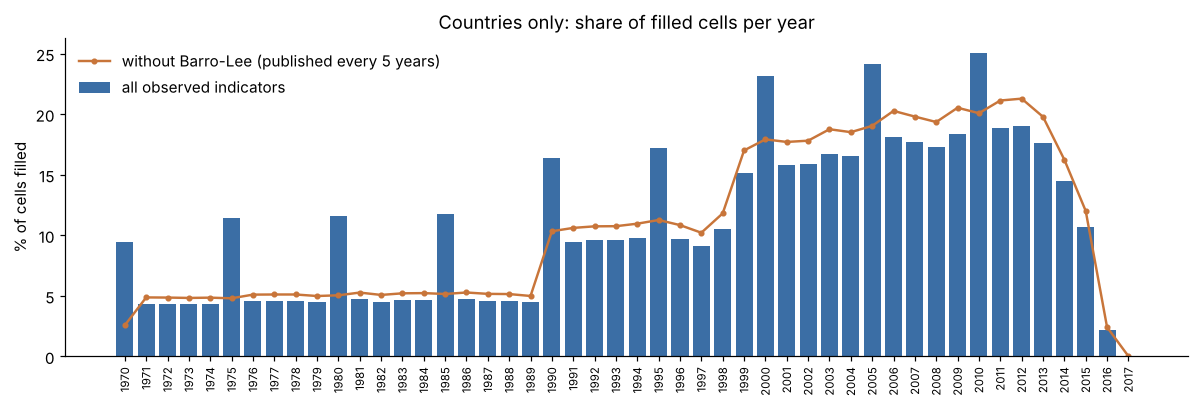

,% cells filled,% filled without Barro-Lee,indicators with >= 1 value,countries with >= 1 value
2008,17.3,19.4,1594,217
2009,18.3,20.5,1754,217
2010,25.0,20.1,2260,217
2011,18.9,21.1,1939,217
2012,19.0,21.3,2031,217
2013,17.7,19.8,1862,217
2014,14.5,16.2,1972,216
2015,10.7,12.0,1749,216
2016,2.2,2.4,419,216
2017,0.0,0.0,40,7


In [11]:
fill_all = df[obs_years].notna().mean() * 100
is_barro = df["Indicator Code"].str.startswith("BAR.")
fill_no_barro = df.loc[~is_barro, obs_years].notna().mean() * 100

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(obs_years))
ax.bar(x, fill_all.values, color=BLUE, label="all observed indicators")
ax.plot(x, fill_no_barro.values, color=ORANGE, marker="o", markersize=3, lw=1.6, label="without Barro-Lee (published every 5 years)")
ax.set_xticks(x); ax.set_xticklabels(obs_years, rotation=90, fontsize=7.5)
ax.set_ylabel("% of cells filled"); ax.set_title("Countries only: share of filled cells per year")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout()
plt.savefig(OUT_DIR / "fill_rate_per_year.png", dpi=160, bbox_inches="tight"); plt.show()

recent = pd.DataFrame({
    "% cells filled": fill_all.loc["2008":].round(1),
    "% filled without Barro-Lee": fill_no_barro.loc["2008":].round(1),
    "indicators with >= 1 value": (df.groupby("Indicator Code")[obs_years].count() > 0).sum().loc["2008":],
    "countries with >= 1 value": (df.groupby("Country Code")[obs_years].count() > 0).sum().loc["2008":],
})
recent

**Reading.**
* The peaks every five years (2000, 2005, **2010**) come from the Barro-Lee education-attainment data, published only for those years.
  Without it (orange line), filling is flat around 20 % from 2005 to 2013.
* **2012 is the best-filled recent year** once that effect is removed; 2013 is close behind.
* After 2013 the decline is steep: 2014 is still usable, **2015 holds half as much as 2012, 2016 is almost empty and 2017 is empty.**
* Every country has at least one value each year up to 2016: what disappears is the **number of indicators**, not countries.

In [12]:
# How much do we keep with a single year versus a window, taking each country's most recent value?
windows = {"2015 only": ["2015"], "2014-2015": ["2014", "2015"], "2013-2015": ["2013", "2014", "2015"],
           "2012-2014": ["2012", "2013", "2014"], "2010-2015": [str(y) for y in range(2010, 2016)]}
coverage = pd.DataFrame({
    "window": list(windows),
    "% (country, indicator) pairs with a value": [round(df[cols].notna().any(axis=1).mean() * 100, 1) for cols in windows.values()],
})
display(coverage)

# The same question for a few indicators that will probably matter for an EdTech company
examples = {"SP.POP.TOTL": "Population", "SP.POP.1524.TO.UN": "Population aged 15-24", "IT.NET.USER.P2": "Internet users per 100",
            "NY.GDP.PCAP.CD": "GDP per capita", "SE.SEC.ENRR": "Gross enrolment, secondary", "SE.TER.ENRR": "Gross enrolment, tertiary",
            "SE.XPD.TOTL.GD.ZS": "Public spending on education, % GDP"}
ex = df[df["Indicator Code"].isin(examples)].groupby("Indicator Code")[[str(y) for y in range(2010, 2017)]].count()
ex.index = ex.index.map(examples)
print("Number of countries with a value, per year:")
ex

,window,"% (country, indicator) pairs with a value"
0,2015 only,10.7
1,2014-2015,17.9
2,2013-2015,21.8
3,2012-2014,23.5
4,2010-2015,34.7


Number of countries with a value, per year:


,2010,2011,2012,2013,2014,2015,2016
Indicator Code,,,,,,,
Internet users per 100,202,204,202,201,201,201,201
GDP per capita,203,203,199,200,197,196,189
"Gross enrolment, secondary",146,150,144,135,135,118,8
"Gross enrolment, tertiary",133,138,136,125,119,100,7
"Public spending on education, % GDP",128,121,113,118,89,45,4
Population aged 15-24,181,181,181,181,181,181,0
Population,215,215,214,214,210,210,210


**Decision: work on 2012–2014, taking for each country and indicator its most recent value in those three years.**

* The teacher asked for three years. **2012–2014 are the three best-filled recent years** once the five-yearly Barro-Lee effect is removed:
  2012 is the best, 2013 close behind, 2014 still usable. 2015 already loses a third of the education data.
* Taking the most recent value over three years rather than a single year more than doubles the coverage (23.5 % of pairs instead of 10.7 % for 2015 alone).
* Two consequences to keep in mind: values do not all date from the same year (the year is kept for each value),
  and **the Barro-Lee attainment data has no value at all in 2012–2014**, so the education level of adults cannot be used.

## 4. Charts on the data coverage

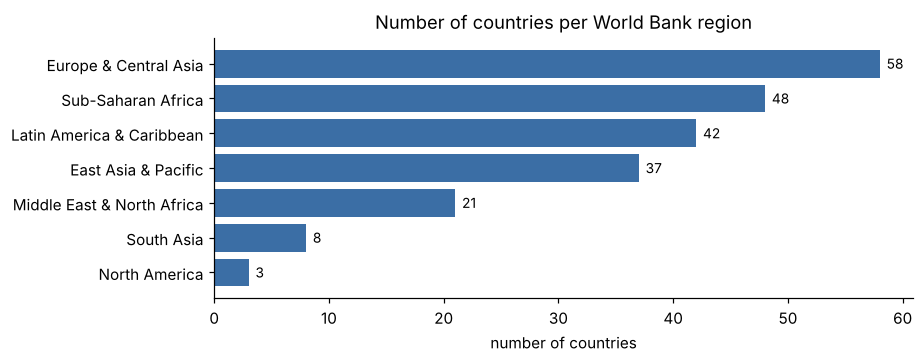

In [13]:
per_region = countries["Region"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.barh(per_region.index, per_region.values, color=BLUE)
for i, v in enumerate(per_region.values):
    ax.text(v + 0.6, i, str(v), va="center", fontsize=9)
ax.set_xlabel("number of countries"); ax.set_title("Number of countries per World Bank region")
plt.tight_layout(); plt.savefig(OUT_DIR / "countries_per_region.png", dpi=160, bbox_inches="tight"); plt.show()

The regions are very unequal in size: *Europe & Central Asia* has 58 countries, *North America* 3. A regional **average** gives each country
the same weight, so it says little about a region of 3 countries, and nothing about market size: population must be looked at alongside.

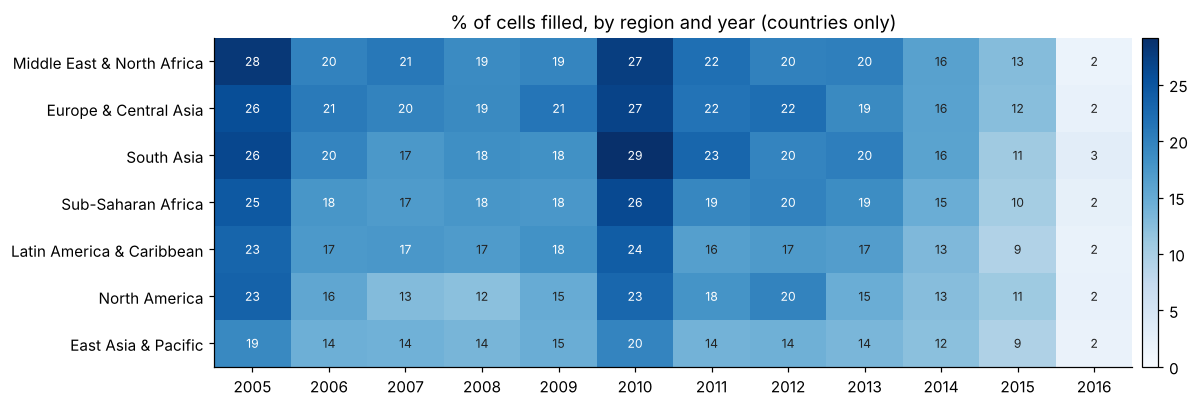

In [14]:
# Is the data equally complete everywhere? Share of filled cells, by region and year
heat_years = [str(y) for y in range(2005, 2017)]
heat = df.groupby("Region")[heat_years].apply(lambda g: g.notna().mean() * 100)
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(heat_years))); ax.set_xticklabels(heat_years)
ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > heat.values.max() * 0.6 else "#222")
ax.set_title("% of cells filled, by region and year (countries only)")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
plt.tight_layout(); plt.savefig(OUT_DIR / "fill_by_region_year.png", dpi=160, bbox_inches="tight"); plt.show()

**Reading.** The gaps between regions are moderate but steady: **East Asia & Pacific is the least documented region every year**
(about 14 % of cells filled in 2011–2013, against about 20 % for Europe & Central Asia, Middle East & North Africa or South Asia).
A region can look less attractive simply because we know less about it: this is a bias to state in the final report,
and a reason to always show how many countries stand behind a regional figure.

## 5. Which indicators to keep?

### 5.1 The rule
An indicator is kept if it passes **two filters**:
1. **Relevance** for our hypothesis (paid online learning for upper-secondary and university students): it says something about
   the *size* of the market, the *educational demand*, the *access* to an online product or the *ability to pay*.
2. **Coverage**: at least one value in 2012–2014 for **at least 60 % of the 217 countries (130 countries)**. Below that,
   comparisons between regions are no longer meaningful.

### 5.2 Coverage of every indicator in 2012–2014

In [15]:
WINDOW = ["2012", "2013", "2014"]
MIN_COUNTRIES = 130

cov = (df.assign(any_value=df[WINDOW].notna().any(axis=1), all_years=df[WINDOW].notna().all(axis=1))
         .groupby(["Indicator Code", "Indicator Name", "Topic"], as_index=False)[["any_value", "all_years"]].sum()
         .rename(columns={"any_value": "countries (>= 1 value)", "all_years": "countries (3 years)"}))
print(f"observed indicators: {len(cov)}")
print(f"with >= {MIN_COUNTRIES} countries in 2012-2014: {(cov['countries (>= 1 value)'] >= MIN_COUNTRIES).sum()}")
print(f"with no value at all in 2012-2014: {(cov['countries (>= 1 value)'] == 0).sum()}")

observed indicators: 3357
with >= 130 countries in 2012-2014: 562
with no value at all in 2012-2014: 936


562 indicators pass the coverage filter (and 936 have no value at all in 2012–2014), but most are variants of each other (female / male / parity index,
population by single year of age…). Relevance does the rest of the work.

### 5.3 The selection

In [16]:
SELECTION = {
    # code                  (family,                 short label)
    "SP.POP.TOTL":         ("1. Market size",        "Population, total"),
    "SP.POP.1524.TO.UN":   ("1. Market size",        "Population aged 15-24"),
    "SP.SEC.UTOT.IN":      ("1. Market size",        "Population of upper-secondary age"),
    "SP.TER.TOTL.IN":      ("1. Market size",        "Population of tertiary age"),
    "SP.POP.GROW":         ("1. Market size",        "Population growth (%)"),
    "SE.SEC.ENRR":         ("2. Education demand",   "Gross enrolment ratio, secondary (%)"),
    "SE.TER.ENRR":         ("2. Education demand",   "Gross enrolment ratio, tertiary (%)"),
    "UIS.E.3":             ("2. Education demand",   "Students in upper secondary (number)"),
    "SE.TER.ENRL":         ("2. Education demand",   "Students in tertiary (number)"),
    "IT.NET.USER.P2":      ("3. Access",             "Internet users per 100 people"),
    "NY.GDP.PCAP.PP.CD":   ("4. Ability to pay",     "GDP per capita, PPP (current intl $)"),
    "SE.TER.PRIV.ZS":      ("4. Ability to pay",     "Share of tertiary students in private institutions (%)"),
}
sel = (pd.DataFrame([(k, *v) for k, v in SELECTION.items()], columns=["Indicator Code", "family", "label"])
         .merge(cov, on="Indicator Code", how="left"))
sel["% of countries"] = (sel["countries (>= 1 value)"] / len(countries) * 100).round(0).astype(int)
assert sel["countries (>= 1 value)"].ge(MIN_COUNTRIES).all(), "an indicator is below the coverage threshold"
sel[["family", "Indicator Code", "label", "countries (>= 1 value)", "countries (3 years)", "% of countries"]]

,family,Indicator Code,label,countries (>= 1 value),countries (3 years),% of countries
0,1. Market size,SP.POP.TOTL,"Population, total",214,210,99
1,1. Market size,SP.POP.1524.TO.UN,Population aged 15-24,181,181,83
2,1. Market size,SP.SEC.UTOT.IN,Population of upper-secondary age,197,196,91
3,1. Market size,SP.TER.TOTL.IN,Population of tertiary age,195,159,90
4,1. Market size,SP.POP.GROW,Population growth (%),214,210,99
5,2. Education demand,SE.SEC.ENRR,"Gross enrolment ratio, secondary (%)",163,110,75
6,2. Education demand,SE.TER.ENRR,"Gross enrolment ratio, tertiary (%)",152,102,70
7,2. Education demand,UIS.E.3,Students in upper secondary (number),172,94,79
8,2. Education demand,SE.TER.ENRL,Students in tertiary (number),158,106,73
9,3. Access,IT.NET.USER.P2,Internet users per 100 people,203,200,94


**Why these twelve.**
* **Market size** — how many potential customers. Total population for scale, the 15–24 age group and the populations of
  upper-secondary and tertiary age for the target itself, growth to know whether the market is expanding.
* **Education demand** — are these young people actually in school? Ratios *and* numbers are both needed:
  a 90 % ratio in Luxembourg and a 60 % ratio in India say nothing about the size of the market.
* **Access** — an online product needs internet. This is the only connectivity indicator still filled after 2009.
* **Ability to pay** — GDP per capita in *purchasing power parity*, because 1,000 dollars do not buy the same thing everywhere;
  and the share of students in private institutions, the best available proxy for families' willingness to pay for education.
  It is also the weakest indicator of the list (137 countries).

The **gross enrolment ratio in primary education** is not selected: primary-school pupils are not the target of our hypothesis.
A group targeting children would add it.

The **income group** of each country (from `country`) is kept alongside: it is not an indicator, but it is useful to split results.

In [17]:
# What was set aside, and why (coverage measured the same way)
def n_countries(codes):
    sub = df[df["Indicator Code"].isin(codes)]
    return int(sub.groupby("Indicator Code")[WINDOW].apply(lambda g: g.notna().any(axis=1).sum()).max()) if len(sub) else 0

pisa_codes = [c for c in df["Indicator Code"].unique() if c.startswith("LO.PISA")]
excluded = pd.DataFrame([
    ["Education attainment of adults (Barro-Lee)", n_countries([c for c in df["Indicator Code"].unique() if c.startswith("BAR.")]), "no value at all in 2012-2014 (published every 5 years)"],
    ["Personal computers per 100 people", n_countries(["IT.CMP.PCMP.P2"]), "no data after 2009"],
    ["Adult literacy rate", n_countries(["SE.ADT.LITR.ZS"]), "too few countries"],
    ["PISA test scores (best-covered PISA indicator)", n_countries(pisa_codes), "too few countries, irregular years"],
    ["Public spending on education, % of GDP", n_countries(["SE.XPD.TOTL.GD.ZS"]), "measures the State's effort, not what families pay"],
    ["Female / male / parity variants", None, "redundant with the 'both sexes' total"],
    ["GDP in constant US$", n_countries(["NY.GDP.PCAP.KD"]), "name inconsistent between files (2005 vs 2010 US$)"],
], columns=["indicator(s)", "countries (>= 1 value)", "reason"])
excluded["countries (>= 1 value)"] = excluded["countries (>= 1 value)"].astype("Int64")
excluded

,indicator(s),countries (>= 1 value),reason
0,Education attainment of adults (Barro-Lee),0,no value at all in 2012-2014 (published every 5 years)
1,Personal computers per 100 people,0,no data after 2009
2,Adult literacy rate,70,too few countries
3,PISA test scores (best-covered PISA indicator),64,"too few countries, irregular years"
4,"Public spending on education, % of GDP",136,"measures the State's effort, not what families pay"
5,Female / male / parity variants,<NA>,redundant with the 'both sexes' total
6,GDP in constant US$,196,name inconsistent between files (2005 vs 2010 US$)


### 5.4 Is the selection equally complete everywhere?

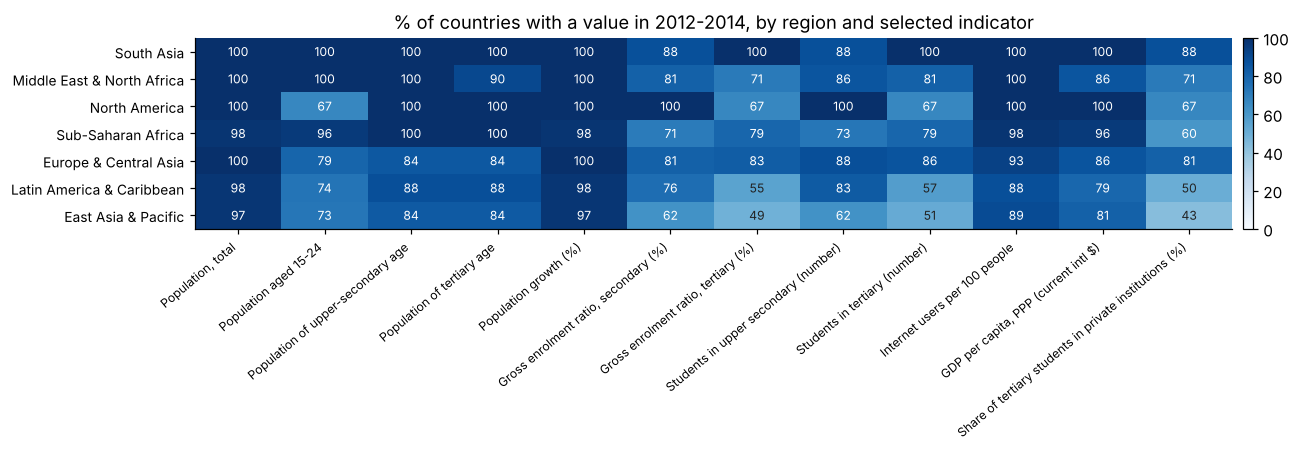

In [18]:
SEL = list(SELECTION)
sub = df[df["Indicator Code"].isin(SEL)].assign(has=lambda d: d[WINDOW].notna().any(axis=1))
heat = sub.pivot_table(index="Region", columns="Indicator Code", values="has", aggfunc="mean") * 100
heat = heat[SEL].loc[heat.mean(axis=1).sort_values(ascending=False).index]
heat.columns = [SELECTION[c][1] for c in heat.columns]

fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto", vmin=0, vmax=100)
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index, fontsize=9)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else "#222")
ax.set_title("% of countries with a value in 2012-2014, by region and selected indicator")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
plt.tight_layout(); plt.savefig(OUT_DIR / "selection_coverage_by_region.png", dpi=160, bbox_inches="tight"); plt.show()

**Reading.** Population, internet and GDP are complete almost everywhere. The gaps are concentrated on **tertiary education**
and on the **share of private institutions**, and above all in **East Asia & Pacific** (about half of the countries have tertiary data)
and **Latin America & Caribbean**. Any regional figure on these indicators must say how many countries stand behind it.

## 6. One row per country: the reference table 2012–2014

For each country and indicator, the **reference value is the mean of the available values over 2012, 2013 and 2014**
(as suggested for this session). A mean smooths year-to-year noise; if only one year is available, that year is used.
The number of years behind each mean is kept.

In [19]:
SEL = list(SELECTION)
LABEL = {c: SELECTION[c][1] for c in SEL}
sub = df[df["Indicator Code"].isin(SEL)].set_index(["Country Code", "Indicator Code"])[WINDOW]

ref = sub.mean(axis=1).unstack("Indicator Code")[SEL]               # mean of the available years (NaN ignored)
n_years = sub.notna().sum(axis=1).unstack("Indicator Code")[SEL]     # how many years behind each mean

table = countries.set_index("Country Code")[["Country Name", "Region", "Income Group"]].join(ref)
table["n_indicators_filled"] = ref.notna().sum(axis=1).reindex(table.index).fillna(0).astype(int)

print("reference table:", table.shape, "(217 countries)")
print("\nhow many years behind each value (all indicators together):")
print(n_years.stack().value_counts().sort_index().rename({0: "no value", 1: "1 year", 2: "2 years", 3: "3 years"}).to_string())
print("\nnumber of the 12 indicators filled per country:")
print(table["n_indicators_filled"].value_counts().sort_index(ascending=False).to_string())

table.to_csv(OUT_DIR / "edstats_reference_table_2012_2014.csv")
table[["Country Name", "Region", "n_indicators_filled"] + SEL[:3] + ["IT.NET.USER.P2", "NY.GDP.PCAP.PP.CD"]].head()

reference table: (217, 16) (217 countries)

how many years behind each value (all indicators together):
no value     430
1 year       150
2 years      190
3 years     1834

number of the 12 indicators filled per country:
n_indicators_filled
12    109
11     27
10     10
9      23
8       9
7      14
6       5
5       2
4       3
3      10
2       5


,Country Name,Region,n_indicators_filled,SP.POP.TOTL,SP.POP.1524.TO.UN,SP.SEC.UTOT.IN,IT.NET.USER.P2,NY.GDP.PCAP.PP.CD
Country Code,,,,,,,,
AFG,Afghanistan,South Asia,12,3.172889e+07,6.801699e+06,2.093147e+06,6.118182,1875.337768
ALB,Albania,Europe & Central Asia,12,2.894866e+06,5.819797e+05,1.660063e+05,57.318653,10813.088791
DZA,Algeria,Middle East & North Africa,10,3.833924e+07,6.794954e+06,1.945458e+06,23.400000,13774.482532
ASM,American Samoa,East Asia & Pacific,2,5.532467e+04,NaN,NaN,NaN,NaN
AND,Andorra,Europe & Central Asia,6,8.081400e+04,NaN,NaN,92.111475,NaN


In [20]:
# Large markets with missing values: they must not be dropped silently
big_incomplete = table[(table["n_indicators_filled"] < 10) & (table["SP.POP.TOTL"] > 5e6)].sort_values("SP.POP.TOTL", ascending=False)
print(f"countries of more than 5 million people with fewer than 10 indicators: {len(big_incomplete)}")
for code_ in big_incomplete.index[:5]:
    missing = [LABEL[c] for c in SEL if pd.isna(table.loc[code_, c])]
    print(f"  {table.loc[code_, 'Country Name']:<12} missing: {', '.join(missing)}")

countries of more than 5 million people with fewer than 10 indicators: 23
  Nigeria      missing: Gross enrolment ratio, tertiary (%), Students in upper secondary (number), Students in tertiary (number), Share of tertiary students in private institutions (%)
  Kenya        missing: Gross enrolment ratio, secondary (%), Gross enrolment ratio, tertiary (%), Students in tertiary (number), Share of tertiary students in private institutions (%)
  Uganda       missing: Gross enrolment ratio, secondary (%), Students in upper secondary (number), Share of tertiary students in private institutions (%)
  Canada       missing: Gross enrolment ratio, tertiary (%), Students in tertiary (number), Share of tertiary students in private institutions (%)
  Iraq         missing: Gross enrolment ratio, secondary (%), Gross enrolment ratio, tertiary (%), Students in upper secondary (number), Students in tertiary (number), Share of tertiary students in private institutions (%)


## 7. Rank the countries

### 7.1 Remove redundancy first
Twelve indicators cannot simply be averaged: if several of them measure the same thing, that thing counts several times.
Spearman correlations (based on ranks, robust to very skewed variables such as population) show which ones overlap.

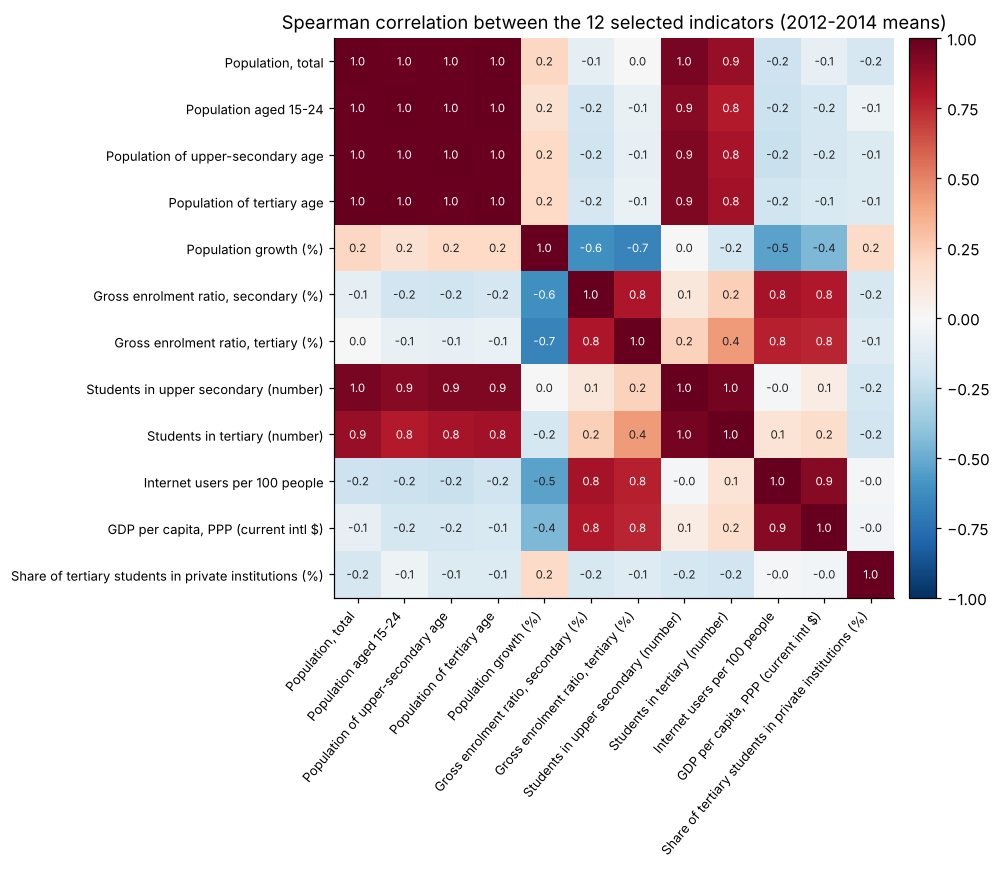

In [21]:
corr = table[SEL].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
labels = [LABEL[c] for c in SEL]
ax.set_xticks(range(len(SEL))); ax.set_xticklabels(labels, rotation=50, ha="right", fontsize=8.5)
ax.set_yticks(range(len(SEL))); ax.set_yticklabels(labels, fontsize=8.5)
for i in range(len(SEL)):
    for j in range(len(SEL)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 else "#222")
ax.set_title("Spearman correlation between the 12 selected indicators (2012-2014 means)")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
plt.tight_layout(); plt.savefig(OUT_DIR / "correlations.png", dpi=160, bbox_inches="tight"); plt.show()

**Reading.**
* The **four population indicators are the same information** (correlation 1.0), and the numbers of students follow them closely (≈ 0.8–1.0).
* **Internet, GDP per capita and enrolment ratios move together** (≈ 0.8–0.9): together they measure the country's level of development.
* **Population growth goes the other way** (≈ −0.4 to −0.7): the youngest, fastest-growing markets are the least equipped.
* The **share of private institutions** is independent of everything else.

So the ranking uses **one indicator per piece of information**:

| Criterion | Indicator | Why this one |
|---|---|---|
| Market size | students in upper secondary + tertiary (number) | the actual number of potential customers, not just people of the right age |
| Access | internet users per 100 people | an online product is useless without internet |
| Ability to pay | GDP per capita, PPP | purchasing power, comparable across countries |
| Education demand | gross enrolment ratio, tertiary | the share of young people who study after secondary school |

Population growth and the share of private institutions are **not scored** (the first works against the others, the second is
the weakest indicator, with values such as 100 % for the United Kingdom that reflect how universities are classified), but they are shown in the results.

### 7.2 The score
Each country gets a **percentile rank** on each criterion (0 = lowest country, 1 = highest), and the score is the **mean of the four**.
Ranks rather than raw values, so that the United States' 31 million students or Luxembourg's GDP do not crush everything else.
Only countries with the four criteria are ranked.

In [22]:
score = table.copy()
score["students"] = score[["UIS.E.3", "SE.TER.ENRL"]].sum(axis=1, min_count=2)   # both levels required
CRITERIA = {"students": "Market size", "IT.NET.USER.P2": "Access", "NY.GDP.PCAP.PP.CD": "Ability to pay", "SE.TER.ENRR": "Education demand"}

ranked = score.dropna(subset=list(CRITERIA)).copy()
pct = pd.DataFrame({name: ranked[col].rank(pct=True) for col, name in CRITERIA.items()})
ranked["score"] = pct.mean(axis=1)
ranked = ranked.join(pct).sort_values("score", ascending=False)
ranked["rank"] = np.arange(1, len(ranked) + 1)
print(f"countries ranked: {len(ranked)} of {len(table)}")

not_ranked = score.drop(ranked.index)
print("largest countries left out (a criterion is missing):",
      ", ".join(not_ranked.sort_values("SP.POP.TOTL", ascending=False)["Country Name"].head(6)))

show = ranked[["rank", "Country Name", "Region", "students", "IT.NET.USER.P2", "NY.GDP.PCAP.PP.CD", "SE.TER.ENRR", "SE.TER.PRIV.ZS", "SP.POP.GROW", "score"]]
show = show.rename(columns={"students": "students (M)", "IT.NET.USER.P2": "internet /100", "NY.GDP.PCAP.PP.CD": "GDP/cap PPP",
                            "SE.TER.ENRR": "tertiary enrol. %", "SE.TER.PRIV.ZS": "private %", "SP.POP.GROW": "pop. growth %"})
show["students (M)"] = show["students (M)"] / 1e6
ranked.to_csv(OUT_DIR / "country_ranking.csv")
show.head(20).round(2)

countries ranked: 132 of 217
largest countries left out (a criterion is missing): Nigeria, Vietnam, Kenya, Algeria, Uganda, Canada


,rank,Country Name,Region,students (M),internet /100,GDP/cap PPP,tertiary enrol. %,private %,pop. growth %,score
Country Code,,,,,,,,,,
USA,1,United States,North America,31.93,73.03,52945.23,90.10,27.80,0.73,0.92
KOR,2,"Korea, Rep.",East Asia & Pacific,5.26,85.47,32781.50,95.59,80.64,0.54,0.89
AUS,3,Australia,East Asia & Pacific,2.49,82.15,44910.29,87.42,8.63,1.63,0.87
NLD,4,Netherlands,Europe & Central Asia,1.54,92.83,48128.54,78.50,13.36,0.34,0.87
DEU,5,Germany,Europe & Central Asia,5.45,84.24,45330.65,63.27,8.09,0.29,0.85
JPN,6,Japan,East Asia & Pacific,7.55,85.61,38517.46,62.41,78.74,-0.15,0.84
GBR,7,United Kingdom,Europe & Central Asia,6.05,89.64,39349.55,57.52,100.00,0.71,0.84
ESP,8,Spain,Europe & Central Asia,3.49,72.54,32758.71,87.23,16.25,-0.19,0.84
DNK,9,Denmark,Europe & Central Asia,0.59,94.29,46476.97,80.67,2.18,0.43,0.84


In [23]:
print("Where do the largest markets stand?")
watch = ["CHN", "IND", "BRA", "IDN", "MEX", "TUR", "RUS", "IRN", "EGY", "PAK", "NGA", "ZAF", "ARG", "POL", "VNM"]
show.loc[[c for c in watch if c in show.index]].round(2)

Where do the largest markets stand?


,rank,Country Name,Region,students (M),internet /100,GDP/cap PPP,tertiary enrol. %,private %,pop. growth %,score
Country Code,,,,,,,,,,
CHN,52,China,East Asia & Pacific,80.83,45.33,12386.31,32.25,14.39,0.50,0.59
IND,77,India,South Asia,84.70,16.23,5281.57,24.60,54.61,1.22,0.47
BRA,37,Brazil,Latin America & Caribbean,17.31,51.38,15852.22,46.99,72.37,0.91,0.66
IDN,73,Indonesia,East Asia & Pacific,16.03,15.53,9979.44,31.01,66.78,1.25,0.51
MEX,55,Mexico,Latin America & Caribbean,7.78,42.53,16834.79,29.15,31.14,1.41,0.59
TUR,26,Turkey,Europe & Central Asia,9.34,47.47,22020.61,78.20,5.99,1.61,0.74
RUS,14,Russian Federation,Europe & Central Asia,10.46,67.43,25424.84,77.59,13.51,0.20,0.81
IRN,42,"Iran, Islamic Rep.",Middle East & North Africa,8.24,30.68,17238.19,59.57,43.66,1.26,0.64
EGY,69,"Egypt, Arab Rep.",Middle East & North Africa,5.79,29.90,10189.04,29.87,18.35,2.22,0.52


### 7.3 Is the ranking robust?

In [24]:
variants = {
    "equal weights":         {"Market size": 0.25, "Access": 0.25, "Ability to pay": 0.25, "Education demand": 0.25},
    "market size x2":        {"Market size": 0.40, "Access": 0.20, "Ability to pay": 0.20, "Education demand": 0.20},
    "market size dominant":  {"Market size": 0.55, "Access": 0.15, "Ability to pay": 0.15, "Education demand": 0.15},
    "without ability to pay":{"Market size": 1/3,  "Access": 1/3,  "Ability to pay": 0.0,  "Education demand": 1/3},
}
top_ref = set(ranked.index[:15])
rows = []
for name, w in variants.items():
    s = sum(ranked[k] * v for k, v in w.items())
    top = s.sort_values(ascending=False).index[:15]
    rows.append({"weighting": name, "same top-15 as equal weights": len(top_ref & set(top)),
                 "top 5": ", ".join(ranked.loc[top[:5], "Country Name"])})
pd.DataFrame(rows)

,weighting,same top-15 as equal weights,top 5
0,equal weights,15,"United States, Korea, Rep., Australia, Netherlands, Germany"
1,market size x2,14,"United States, Korea, Rep., Japan, Germany, Australia"
2,market size dominant,10,"United States, Korea, Rep., Japan, Russian Federation, United Kingdom"
3,without ability to pay,14,"Korea, Rep., United States, Australia, Netherlands, Spain"


**Reading.** With moderate changes of weights, the top 15 barely moves (14 of 15 countries kept). Only when market size
dominates (55 %) does it change noticeably (10 of 15 kept), with Japan, Russia and the United Kingdom moving up.
The weights matter less than the **choice of criteria**: three of the four measure the level of development,
so the score mostly rewards rich countries. That is a limit to state, not a hidden flaw.

In [25]:
by_region = ranked.groupby("Region").agg(countries_ranked=("score", "size"), median_score=("score", "median"),
                                         best_country=("Country Name", "first")).sort_values("median_score", ascending=False)
by_region["countries in region"] = table.groupby("Region").size()
by_region.round(2)

,countries_ranked,median_score,best_country,countries in region
Region,,,,
North America,2,0.76,United States,3
Europe & Central Asia,45,0.68,Netherlands,58
East Asia & Pacific,15,0.59,"Korea, Rep.",37
Middle East & North Africa,12,0.55,Saudi Arabia,21
Latin America & Caribbean,20,0.51,Argentina,42
South Asia,7,0.37,India,8
Sub-Saharan Africa,31,0.18,South Africa,48


## 8. Charts

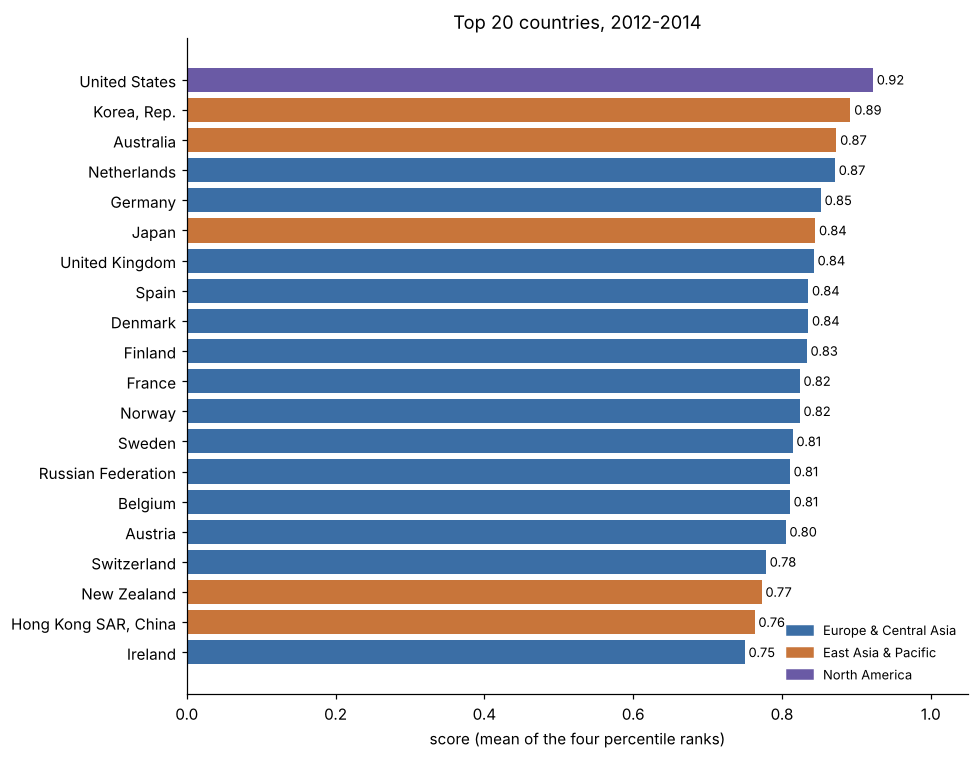

In [26]:
REGION_COLORS = {"Europe & Central Asia": "#3b6ea5", "East Asia & Pacific": "#c8753a", "Latin America & Caribbean": "#4f9a62",
                 "Middle East & North Africa": "#a5486b", "North America": "#6a5aa5", "South Asia": "#b89a2c", "Sub-Saharan Africa": "#5a8f9e"}
top = ranked.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top["Country Name"], top["score"], color=[REGION_COLORS[r] for r in top["Region"]])
for i, v in enumerate(top["score"]):
    ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=8.5)
ax.set_xlim(0, 1.05); ax.set_xlabel("score (mean of the four percentile ranks)")
ax.set_title("Top 20 countries, 2012-2014")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for r, c in REGION_COLORS.items() if r in set(top["Region"])]
ax.legend(handles, [r for r in REGION_COLORS if r in set(top["Region"])], frameon=False, loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.savefig(OUT_DIR / "top20_ranking.png", dpi=160, bbox_inches="tight"); plt.show()

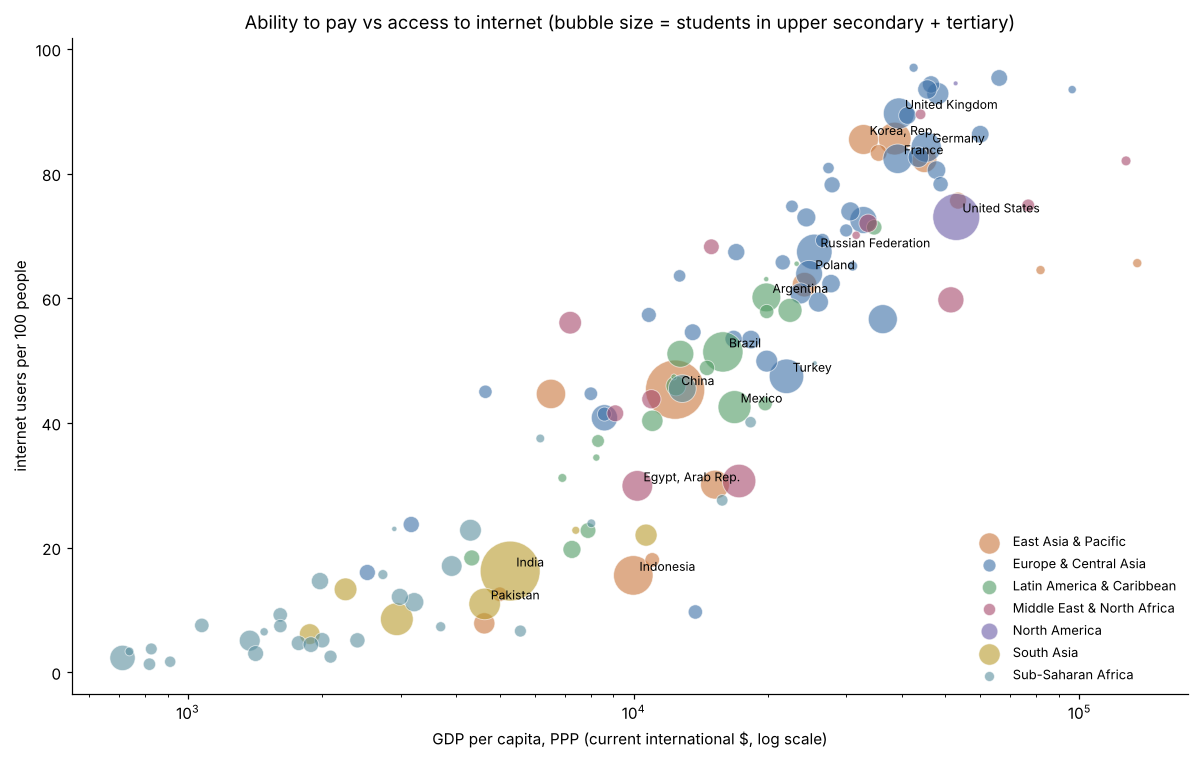

In [27]:
# The trade-off in one picture: purchasing power vs internet access, bubble size = number of students
fig, ax = plt.subplots(figsize=(11, 7))
for region, g in ranked.groupby("Region"):
    ax.scatter(g["NY.GDP.PCAP.PP.CD"], g["IT.NET.USER.P2"], s=np.sqrt(g["students"]) / 6, alpha=0.6,
               color=REGION_COLORS[region], edgecolor="white", linewidth=0.6, label=region)
for code_ in ["USA", "CHN", "IND", "BRA", "IDN", "TUR", "RUS", "DEU", "KOR", "MEX", "POL", "ARG", "GBR", "FRA", "PAK", "EGY"]:
    if code_ in ranked.index:
        r = ranked.loc[code_]
        ax.annotate(r["Country Name"], (r["NY.GDP.PCAP.PP.CD"], r["IT.NET.USER.P2"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("GDP per capita, PPP (current international $, log scale)"); ax.set_ylabel("internet users per 100 people")
ax.set_title("Ability to pay vs access to internet (bubble size = students in upper secondary + tertiary)")
leg = ax.legend(frameon=False, fontsize=8.5, loc="lower right", markerscale=0.5)
plt.tight_layout(); plt.savefig(OUT_DIR / "gdp_vs_internet.png", dpi=160, bbox_inches="tight"); plt.show()

**Reading.** Countries line up along a diagonal: purchasing power and internet access rise together.
The **largest bubbles (China, India, Indonesia, Brazil) sit in the middle or lower part**: huge numbers of students, but limited access and purchasing power.
This is the strategic choice the data cannot make for the company: **small, rich and saturated markets**, or **large markets that are still catching up**.

## Summary of the session

| Step | Result |
|---|---|
| 1. Indicator codes | 53 codes differed by a space or letter case; after normalisation **3,665 / 3,665 match**. |
| 2. Countries only, no projections | 25 aggregates and 308 projection indicators removed: **217 countries**, populations add up to the world total. |
| 3. Period | **2012–2014**, the three best-filled recent years. |
| 4. Indicators | **12 indicators** in four families (market size, education demand, access, ability to pay), each filled for at least 137 countries. |
| 5. Table | One row per country, **mean of 2012–2014** for each indicator. |
| 6. Ranking | Score on 4 non-redundant criteria; robust to the weights. Top: United States, South Korea, Australia, Netherlands, Germany. Best-ranked large emerging markets: Poland (24th), Argentina (25th), Turkey (26th), Brazil (37th). |
| 7. Charts | Coverage per year and region · correlations · top 20 · purchasing power vs internet. |

**Limits to state:** data from 2012–2014; the score mostly rewards rich countries; competition, language and prices are not in the data;
large markets such as Nigeria and Canada cannot be ranked because a criterion is missing.

**Files produced:** `edstats_reference_table_2012_2014.csv` (217 countries × 12 indicators) and `country_ranking.csv`.